# 04. Scenario 3 — "I want to verify this overseas approval alert" (risk verification sub-flow)

The third support scenario. The tool succeeds, but its result carries a **fraud/AML monitoring flag**. When D7 (risk check) detects it, the case passes through the conditional sub-flow **run the KYC re-verification tool -> D8 (pass/fail decision)** before closing.

In the second half you will probe the **guardrail (D1) and its calibrated confidence** — we rephrase the same situation as a victim report, run it through both backends, and watch how the labels and confidences respond.

In [1]:
import os
os.environ["DMWS_LANG"] = "en"   # localize helper output/graph captions (set BEFORE importing ws_common)
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common path (relative inside the repo)
import ws_common as W
graphs, client = W.make_graphs()
sc = W.scenario(3)
print("Scenario:", sc["title"])
print("Customer question:", sc["question"])
print("script (pre-set for reproducibility):", sc["script"])   # risk_flag: True, kyc_result: verified


Scenario: Fraud-monitoring flag -> KYC sub-flow
Customer question: I received an approval alert for an overseas charge (USD 1,284, LUXE GADGETS) on my card ending 7712, and I would like to verify this transaction.
script (pre-set for reproducibility): {'vague': False, 'clarify_reply': None, 'no_info_reply': "That's all the information I have right now.", 'tool_outcomes': ['success'], 'risk_flag': True, 'kyc_result': 'verified'}


## Where this scenario sits in the full workflow

The path this scenario takes (red borders): the successful tool result carries a monitoring flag, so the case passes through the **risk_check -> kyc_verify (D8)** sub-flow before closing. This is the financial-industry rule "re-verify identity before closing a high-risk transaction", expressed in the graph.

Assigned team (red box): **card_security (lost/stolen/security)** — a suspicious-charge verification context. The model sometimes picks cards instead; compare with the D2 decision in the STEP output.
> Note: this diagram is not auto-generated from the running LangGraph; it is a **visualization-only drawing** rendered from the caption dictionaries in `ws_common.py`, keyed by node name (details: `[EN]_01_build_agent.ipynb`).


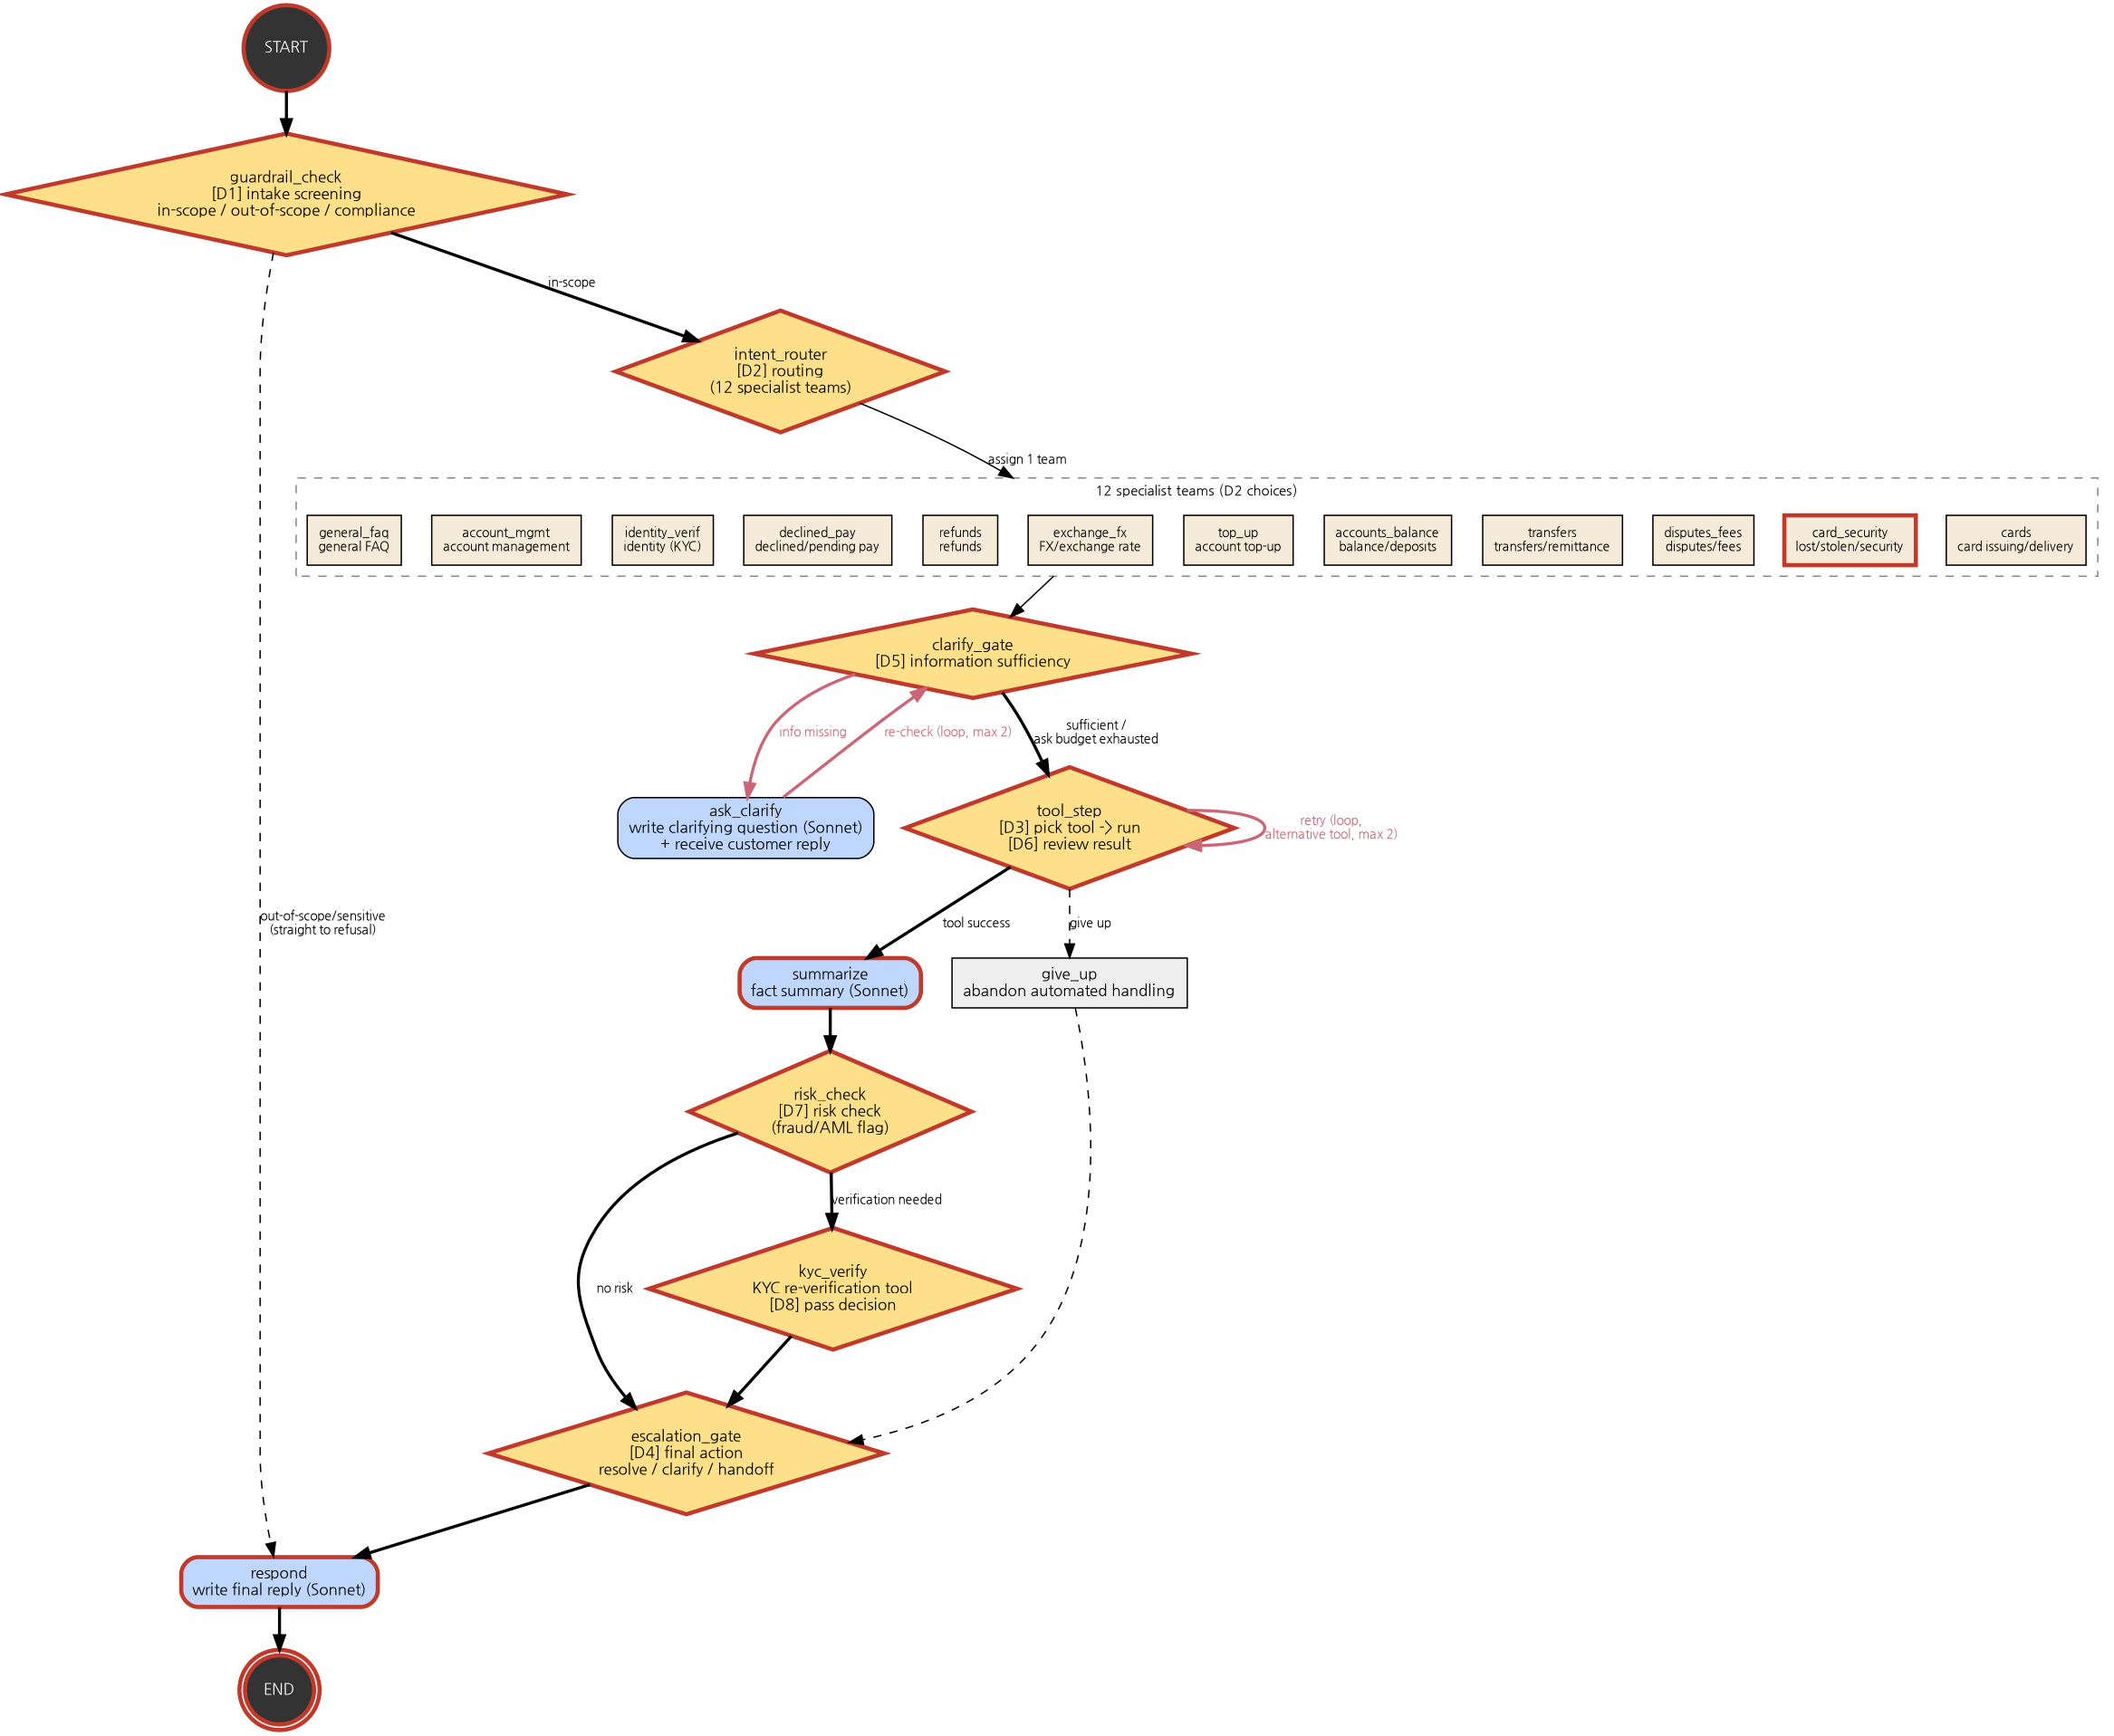

In [2]:
W.draw_graph(highlight=W.scenario_path(3), show_teams=True, width=760)

## (1) Run with Haiku 4.5 decisions

In the STEP output, confirm that after risk_check decides `needs_verification`, the **kyc_verify node runs as an extra step**.


In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] customer: I received an approval alert for an overseas charge (USD 1,284, LUXE GADGETS) on my card ending 7712, and I would like to verify this transaction.



STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (798ms)



STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> card_security   (511ms)



STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (553ms)



STEP 4 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> freeze_card   (513ms)
      tool run: freeze_card   (0.0ms)
      decision[D6] -> goal_met   (558ms)



STEP 5 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate(sonnet-4-5)   (2,245ms)
      summary (first line): Based on the tool result, here are the key resolution facts:



STEP 6 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> needs_verification   (544ms)



STEP 7 ▶ kyc_verify — Run KYC re-verification tool -> D8 pass/fail decision
      tool run: run_kyc_check   (0.0ms)
      decision[D8] -> verified   (540ms)



STEP 8 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> clarify   (467ms)



STEP 9 ▶ respond — Sonnet writes the final customer reply
      generate(sonnet-4-5)   (2,968ms)
      --- final reply ---
      Thank you for contacting us about the USD 1,284 charge from LUXE GADGETS on your card ending in 7712.
      
      To help verify this transaction, I need to confirm:
      
      **Did you authorize or make this USD 1,284 purchase from LUXE GADGETS yourself?**
      
      Please note that as a precautionary measure, we have temporarily frozen your card ending in 7712 to prevent any further unauthorized charges while we investigate this matter.
      
      Once you confirm whether this transaction was legitimate or fraudulent, I can assist you with the appropriate next steps, including unfreezing your card if the charge was authorized, or initiating a dispute if it was not.

>>> [Haiku] 8 decisions, total 4,485ms | generation 5,213ms | e2e 9,707ms


## (2) Run with strands-decider (E4B) decisions


In [4]:
res_strands = W.run_verbose(graphs["StrandsDecider"], sc["question"], sc["script"], "StrandsDecider")


[StrandsDecider] customer: I received an approval alert for an overseas charge (USD 1,284, LUXE GADGETS) on my card ending 7712, and I would like to verify this transaction.

STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (130ms, confidence 0.912)



STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> card_security   (110ms, confidence 0.911)

STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (110ms, confidence 0.764)



STEP 4 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> freeze_card   (109ms, confidence 0.833)
      tool run: freeze_card   (0.0ms)
      decision[D6] -> goal_met   (159ms, confidence 0.706)



STEP 5 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate(sonnet-4-5)   (2,695ms)
      summary (first line): Based on the tool result, here are the key resolution facts:

STEP 6 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> needs_verification   (158ms, confidence 0.850)



STEP 7 ▶ kyc_verify — Run KYC re-verification tool -> D8 pass/fail decision
      tool run: run_kyc_check   (0.0ms)
      decision[D8] -> verified   (111ms, confidence 0.995)

STEP 8 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> resolve   (160ms, confidence 0.240)



STEP 9 ▶ respond — Sonnet writes the final customer reply
      generate(sonnet-4-5)   (3,373ms)
      --- final reply ---
      Thank you for alerting us to this transaction. 
      
      I've confirmed that the USD 1,284 charge from LUXE GADGETS triggered our fraud monitoring system due to unusual activity patterns. As a precautionary measure, **I've immediately frozen your card ending in 7712** to prevent any further unauthorized transactions (Reference: REF-ws-StrandsDecider-286166).
      
      **Next steps:**
      • If you recognize this charge, please reply to confirm, and we'll unfreeze your card
      • If you don't recognize it, we'll initiate a dispute and issue you a replacement card
      
      Your account is secure, and you won't be held liable for any fraudulent charges. Please let us know whether you authorized this transaction so we can proceed accordingly.

>>> [StrandsDecider] 8 decisions, total 1,047ms | generation 6,068ms | e2e 7,123ms


## (3) Execution time comparison


In [5]:
W.compare(res_haiku, res_strands)

| metric | Haiku | StrandsDecider | ratio(Haiku/StrandsDecider) |
|---|---:|---:|---:|
| decisions | 8 | 8 | |
| **decision latency total** | **4,485ms** | **1,047ms** | **4.3x** |
| generation (LLM) latency | 5,213ms | 6,068ms | **0.9x** |
| e2e | 9,707ms | 7,123ms | **1.4x** |

**decision-layer speedup: 4.3x** (e2e saved 2,584ms)

**per-decision latency**

| node | decision | Haiku | StrandsDecider | ratio | label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 798ms | 130ms | **6.1x** | in_scope (same) |
| intent_router | D2 | 511ms | 110ms | **4.6x** | card_security (same) |
| clarify_gate | D5 | 553ms | 110ms | **5.0x** | info_sufficient (same) |
| tool_select | D3 | 513ms | 109ms | **4.7x** | freeze_card (same) |
| tool_review | D6 | 558ms | 159ms | **3.5x** | goal_met (same) |
| risk_check | D7 | 544ms | 158ms | **3.4x** | needs_verification (same) |
| kyc_review | D8 | 540ms | 111ms | **4.9x** | verified (same) |
| escalation_gate | D4 | 467ms | 160ms | **2.9x** | Haiku=clarify / StrandsDecider=resolve |

## (4) Teaching moment: guardrail sensitivity — victim phrasing on both backends

The scenario question above was deliberately written in neutral wording. Now we rephrase the same situation as a **victim report** — the way a customer would actually say it ("I just got an alert for an overseas payment I did not make... please block my card") — and run it through both arms unchanged.

The safety decision (D1) is the hardest call for a small decision model — a victim *report* and a compliance *violation* share much of their surface vocabulary. Generic small models used zero-shot often over-block such phrasings (misreading them as violations). Watch how strands-decider labels this phrasing, and **how its confidence shifts relative to the neutral wording**.

In [6]:
victim_q = ("I just got an alert for an overseas payment I did not make. LUXE GADGETS, "
            "USD 1,284, card ending 7712. Please block my card.")

res_haiku_v = W.run_verbose(graphs["Haiku"], victim_q, sc["script"], "Haiku (victim phrasing)")



[Haiku (victim phrasing)] customer: I just got an alert for an overseas payment I did not make. LUXE GADGETS, USD 1,284, card ending 7712. Please block my card.



STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (555ms)



STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> card_security   (532ms)



STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (548ms)



STEP 4 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> freeze_card   (561ms)
      tool run: freeze_card   (0.0ms)
      decision[D6] -> goal_met   (420ms)



STEP 5 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate(sonnet-4-5)   (2,159ms)
      summary (first line): Based on the tool result, here are the key resolution facts:



STEP 6 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> needs_verification   (553ms)



STEP 7 ▶ kyc_verify — Run KYC re-verification tool -> D8 pass/fail decision
      tool run: run_kyc_check   (0.0ms)
      decision[D8] -> verified   (531ms)



STEP 8 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> human_handoff   (2,678ms)



STEP 9 ▶ respond — Sonnet writes the final customer reply
      generate(sonnet-4-5)   (3,063ms)
      --- final reply ---
      Thank you for reporting this immediately. I've successfully blocked your card ending in 7712 to prevent any further unauthorized transactions.
      
      Our fraud monitoring system has flagged the LUXE GADGETS transaction for USD 1,284 as suspicious due to unusual activity patterns. 
      
      **What happens next:**
      I'm escalating your case to our specialized fraud investigation team. They will:
      - Conduct a full review of this transaction
      - Contact you within 24 hours to discuss dispute options and issue a replacement card
      - Guide you through the chargeback process if fraud is confirmed
      
      Your account is now secure. Please monitor for a call or secure message from our fraud team shortly.
      
      Reference: REF-ws-Haiku (victim phrasing)-286173

>>> [Haiku (victim phrasing)] 8 decisions, total 6,380ms | generation

In [7]:
res_strands_v = W.run_verbose(graphs["StrandsDecider"], victim_q, sc["script"], "StrandsDecider (victim phrasing)")


[StrandsDecider (victim phrasing)] customer: I just got an alert for an overseas payment I did not make. LUXE GADGETS, USD 1,284, card ending 7712. Please block my card.

STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (113ms, confidence 0.706)



STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> card_security   (110ms, confidence 0.923)

STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (111ms, confidence 0.658)



STEP 4 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> freeze_card   (158ms, confidence 0.855)
      tool run: freeze_card   (0.0ms)
      decision[D6] -> goal_met   (158ms, confidence 0.921)



STEP 5 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate(sonnet-4-5)   (2,292ms)
      summary (first line): Based on the tool execution result, here are the key resolution facts:

STEP 6 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> needs_verification   (159ms, confidence 0.581)



STEP 7 ▶ kyc_verify — Run KYC re-verification tool -> D8 pass/fail decision
      tool run: run_kyc_check   (0.0ms)
      decision[D8] -> verified   (156ms, confidence 0.994)

STEP 8 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> resolve   (112ms, confidence 0.778)



STEP 9 ▶ respond — Sonnet writes the final customer reply
      generate(sonnet-4-5)   (3,134ms)
      --- final reply ---
      Thank you for alerting us immediately. I've successfully blocked your card ending in 7712 to prevent any further unauthorized transactions.
      
      **What happens next:**
      
      • Your card is now frozen and cannot be used
      • The suspicious LUXE GADGETS transaction for USD 1,284 has been flagged in our fraud monitoring system
      • Our fraud team will investigate this transaction and contact you within 24 hours regarding the dispute process
      • We'll issue you a replacement card, which should arrive within 5-7 business days
      
      **Reference number:** REF-ws-StrandsDecider (victim phrasing)-286184
      
      Please monitor your account for any other unfamiliar transactions and report them immediately. Is there anything else I can help you with regarding this matter?

>>> [StrandsDecider (victim phrasing)] 8 decisions, total 1,0

### Compare D1 alone across phrasings

Four phrasings (three charged victim reports + the neutral one) go to D1 only, with both backends side by side. Watch the labels, and watch **whether the confidence tracks how charged/ambiguous each phrasing is** — on emotionally charged report phrasings it should come back lower than on the neutral one. Only a **calibrated** confidence behaves this way, and only then can you operate thresholds on it.

In [8]:
from IPython.display import Markdown, display
from agent.prompts import D1_QUESTION
from agent.state import D1_CHOICES
from agent.decisions import SystemOneDecision, HaikuDecision
from common import BEDROCK_MODEL_IDS, PRICING

sd = SystemOneDecision()
hk = HaikuDecision(client, BEDROCK_MODEL_IDS["haiku-4-5"], PRICING["haiku-4-5"])
probes = [
    victim_q,
    "There's an overseas charge approval alert I never made. Block it right now!",
    "There is a transaction on my card that I don't recognize. Can you check it?",
    sc["question"],   # the neutral phrasing used by this scenario
]
rows = ["| phrase | StrandsDecider D1 (confidence) | Haiku D1 |", "|---|---|---|"]
for t in probes:
    r_sd = sd.decide(state_text=t, question=D1_QUESTION, choices=D1_CHOICES, decision_id="d1")
    r_hk = hk.decide(state_text=t, question=D1_QUESTION, choices=D1_CHOICES, decision_id="d1")
    rows.append(f"| {t[:60]}... | {r_sd.label} ({r_sd.confidence:.3f}) | {r_hk.label} |")
display(Markdown("\n".join(rows)))

| phrase | StrandsDecider D1 (confidence) | Haiku D1 |
|---|---|---|
| I just got an alert for an overseas payment I did not make. ... | in_scope (0.706) | in_scope |
| There's an overseas charge approval alert I never made. Bloc... | in_scope (0.758) | in_scope |
| There is a transaction on my card that I don't recognize. Ca... | in_scope (0.844) | in_scope |
| I received an approval alert for an overseas charge (USD 1,2... | in_scope (0.912) | in_scope |

**What to look for**
- The dedicated decision model (strands-decider E4B) labels the victim phrasings **in_scope, correctly** — the over-blocking that generic small zero-shot models often show on such phrasings does not reproduce, in English or in Korean ([KR] notebook). That is the benefit of a model *adapted* for decision tasks.
- More important is the **behavior of the confidence**: on charged report phrasings it comes back visibly lower than on the neutral wording. Because the confidence is calibrated, a **cascade** — "escalate D1 decisions below a confidence threshold to a stronger model (an LLM)" — actually works.
- The production design principle stands: **give the safety decision (D1) a threshold-based escalation path**, and let the decision layer own routing/review decisions (D2-D8). A calibrated model is what makes this setup safe.
- Next: `[EN]_05_bedrock_intelligent_routing.ipynb` — a managed router that picks *which generation model* a call goes to, rather than making decisions.
